# Sparse representation and dictionary learning

Instead of describing an image patch with every pixel value, we can represent it as a combination of a few reusable patterns, or **atoms**:

$$A \approx DX.$$

The columns of `A` are image patches, the columns of `D` are dictionary atoms, and the columns of `X` contain their coefficients. A representation is **sparse** when most coefficients are zero. We will build an overcomplete cosine dictionary, find sparse codes with matching pursuit, compare reconstruction quality and storage at different sparsities, then update the dictionary to better fit the image patches.

## 1. Show the original color image

We will first display the original image in color. The sparse coding demonstration uses a smaller grayscale copy, divided into non-overlapping patches so it is straightforward to put the reconstruction back together.

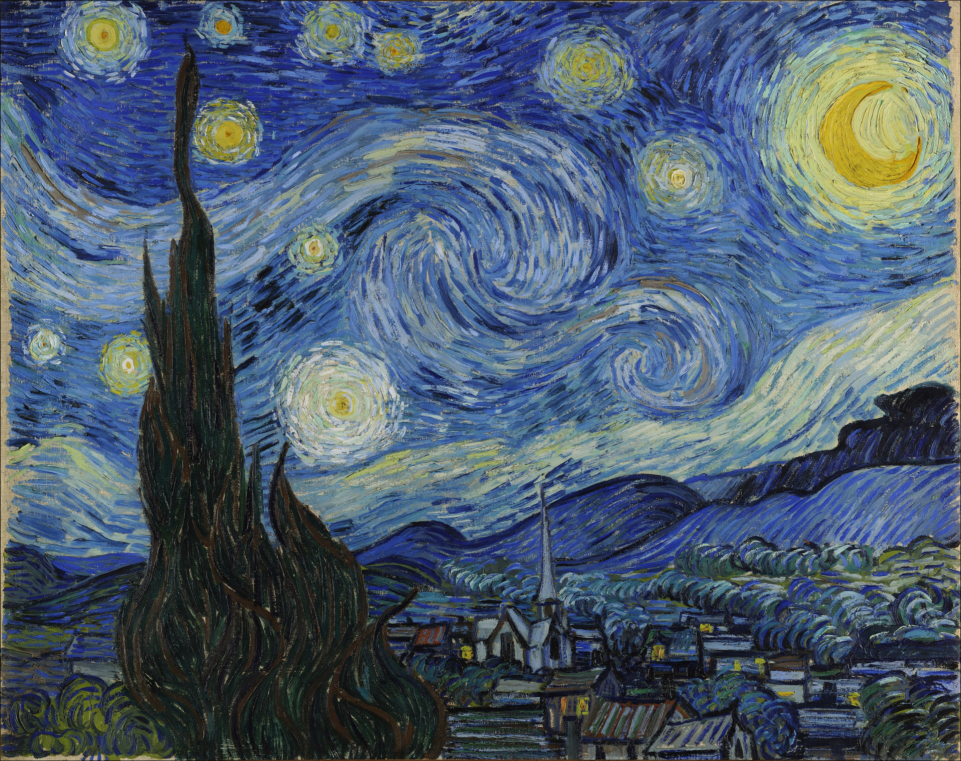

In [1]:
using LinearAlgebra
using Images
using ImageIO

image_path = joinpath(@__DIR__, "..", "images", "starry-night.jpg")
original = load(image_path)
original

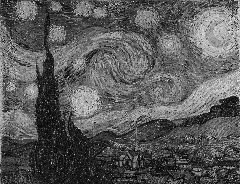

In [2]:
patch_size = 8
gray_image = Float64.(Gray.(original[1:16:end, 1:16:end]))
height = (size(gray_image, 1) ÷ patch_size) * patch_size
width = (size(gray_image, 2) ÷ patch_size) * patch_size
gray_image = gray_image[1:height, 1:width]
Gray.(gray_image)

Each patch has `patch_size × patch_size` pixel values. We arrange each flattened patch as a column of `A`, so `A` has `patch_size^2` rows and one column per image patch.

In [3]:
function image_patches(image, patch_size)
    height, width = size(image)
    rows = 1:patch_size:height
    cols = 1:patch_size:width
    patches = Matrix{Float64}(undef, patch_size^2, length(rows) * length(cols))
    index = 1

    for col in cols, row in rows
        patches[:, index] = vec(image[row:row+patch_size-1, col:col+patch_size-1])
        index += 1
    end

    patches
end

A = image_patches(gray_image, patch_size)
size(A)

(64, 690)

## 2. Create an overcomplete dictionary

An orthonormal basis for `patch_size^2`-dimensional patches would have `patch_size^2` atoms. An **overcomplete dictionary** has more atoms than dimensions, giving the sparse coder more possible patterns to choose from. Here, the cosine dictionary samples a configurable frequency grid and normalizes its atoms.

In [4]:
function cosine_dictionary(patch_size; frequencies=2 * patch_size)
    frequency_grid = range(0, patch_size - 1; length=frequencies)
    one_dimensional = [cospi((position - 0.5) * frequency / patch_size)
                       for position in 1:patch_size, frequency in frequency_grid]
    one_dimensional ./= sqrt.(sum(abs2, one_dimensional; dims=1))

    atom_count = frequencies^2
    dictionary = Matrix{Float64}(undef, patch_size^2, atom_count)
    atom = 1
    for vertical in 1:frequencies, horizontal in 1:frequencies
        dictionary[:, atom] = vec(one_dimensional[:, horizontal] * one_dimensional[:, vertical]')
        atom += 1
    end

    dictionary
end

D = cosine_dictionary(patch_size)
(size(D), maximum(abs.(vec(sum(abs2, D; dims=1)) .- 1)))

((64, 256), 6.661338147750939e-16)

Each dictionary column has unit norm. `D` has one row per patch value and one column per atom, with more columns than rows, so it is overcomplete. There are multiple possible explanations for each patch; we seek one that uses only a few atoms.

## 3. Sparse coding with matching pursuit

Matching pursuit repeatedly selects the atom most correlated with the current patch residual, records its coefficient, and subtracts that contribution. After `s` steps, at most `s` dictionary atoms are used for each patch. This greedy method is simple and fast to demonstrate; it does not always find the globally sparsest possible code.

In [5]:
function matching_pursuit(D, A, sparsities)
    max_sparsity = maximum(sparsities)
    coefficients = zeros(Float64, size(D, 2), size(A, 2))
    residual = copy(A)
    used = falses(size(D, 2), size(A, 2))
    snapshots = Dict{Int, Matrix{Float64}}()

    for step in 1:max_sparsity
        scores = abs.(D' * residual)
        scores[used] .= 0
        selected = [argmax(view(scores, :, patch)) for patch in axes(A, 2)]
        amplitudes = [dot(view(D, :, selected[patch]), view(residual, :, patch)) for patch in axes(A, 2)]

        for patch in axes(A, 2)
            coefficients[selected[patch], patch] = amplitudes[patch]
            used[selected[patch], patch] = true
        end

        residual .-= D[:, selected] .* reshape(amplitudes, 1, :)
        if step in sparsities
            snapshots[step] = copy(coefficients)
        end
    end

    snapshots
end

sparsities = [2, 4, 8]
sparse_codes = matching_pursuit(D, A, sparsities)
[(sparsity=s, nonzeros_per_patch=count(x -> !iszero(x), sparse_codes[s]) / size(A, 2)) for s in sparsities]

3-element Vector{@NamedTuple{sparsity::Int64, nonzeros_per_patch::Float64}}:
 (sparsity = 2, nonzeros_per_patch = 2.0)
 (sparsity = 4, nonzeros_per_patch = 4.0)
 (sparsity = 8, nonzeros_per_patch = 8.0)

The coefficient matrix `X` has one row per dictionary atom and one column per image patch. Only a few entries in each column are nonzero, even though the dictionary is overcomplete.

## 4. Compare sparsity, quality, and storage

We combine reconstructed patches back into an image. With only a few atoms per patch, some texture and edges are lost; allowing more atoms usually improves the reconstruction. Our simple storage estimate includes the dictionary once, plus one coefficient and one atom index per nonzero. It compares with storing all patch pixel values and ignores file-format overhead.

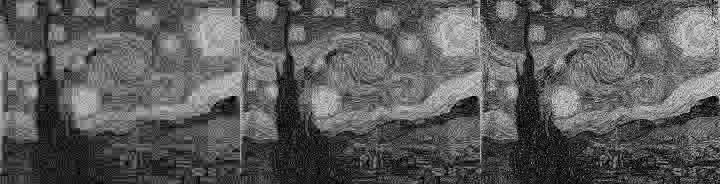

In [6]:
function assemble_image(patches, patch_size, height, width)
    image = zeros(Float64, height, width)
    index = 1
    for col in 1:patch_size:width, row in 1:patch_size:height
        image[row:row+patch_size-1, col:col+patch_size-1] = reshape(patches[:, index], patch_size, patch_size)
        index += 1
    end
    image
end

reconstructions = Dict(s => assemble_image(D * sparse_codes[s], patch_size, height, width) for s in sparsities)
Gray.(clamp.(hcat((reconstructions[s] for s in sparsities)...), 0, 1))

In [7]:
patch_errors = [norm(A - D * sparse_codes[s]) / norm(A) for s in sparsities]
patch_count = size(A, 2)
raw_values = length(A)
storage_ratios = [(length(D) + 2 * s * patch_count) / raw_values for s in sparsities]
[(sparsity=s, relative_error=patch_errors[i], estimated_storage_ratio=storage_ratios[i]) for (i, s) in enumerate(sparsities)]

3-element Vector{@NamedTuple{sparsity::Int64, relative_error::Float64, estimated_storage_ratio::Float64}}:
 (sparsity = 2, relative_error = 0.27940888071045655, estimated_storage_ratio = 0.4335144927536232)
 (sparsity = 4, relative_error = 0.24279655838763156, estimated_storage_ratio = 0.4960144927536232)
 (sparsity = 8, relative_error = 0.19285600114362567, estimated_storage_ratio = 0.6210144927536232)

The overcomplete dictionary has a one-time storage cost, so sparse coding is not automatically compression—especially for a small image or a dense code. For a fixed dictionary, each added atom can only reduce or maintain the least-squares residual when its coefficient is selected by matching pursuit. The storage estimate helps show when that accuracy gain is worth the extra coefficients.

## 5. Adapt the dictionary to the image

A fixed cosine dictionary is convenient, but its patterns are not tailored to this image. **Dictionary learning** alternates between finding sparse codes and updating the atoms to better represent the training patches. Below is one simple method-of-optimal-directions (MOD) update: with the sparse codes held fixed, solve a regularized least-squares problem for the dictionary, then normalize its atoms and rescale their coefficients.

In [8]:
training_codes = sparse_codes[4]
ridge = 1e-6
dictionary_fit = (A * training_codes') / (training_codes * training_codes' + ridge * I)
atom_norms = vec(sqrt.(sum(abs2, dictionary_fit; dims=1)))
learned_dictionary = copy(dictionary_fit)
for atom in axes(learned_dictionary, 2)
    if atom_norms[atom] > sqrt(eps())
        learned_dictionary[:, atom] ./= atom_norms[atom]
    else
        learned_dictionary[:, atom] = D[:, atom]
        atom_norms[atom] = 0
    end
end
learned_codes = Diagonal(atom_norms) * training_codes

fixed_dictionary_error = norm(A - D * training_codes) / norm(A)
learned_dictionary_error = norm(A - learned_dictionary * learned_codes) / norm(A)
(fixed_dictionary_error=fixed_dictionary_error, learned_dictionary_error=learned_dictionary_error)

(fixed_dictionary_error = 0.24279655838763156, learned_dictionary_error = 0.18553854560613345)

This update is chosen to reduce squared reconstruction error for the current codes, so the learned-dictionary error should be no greater (up to numerical tolerance). It is one alternating-update step, not a complete dictionary-learning algorithm: repeating sparse coding and dictionary updates can adapt the atoms further, but may also overfit the training image.

## Your turn

1. Change `sparsities` and compare the reconstruction with the storage estimate. How many atoms per patch look like a useful trade-off?
2. Visualize individual dictionary atoms by reshaping columns of `D` into `8 × 8` patches. Which atoms capture broad shading, and which capture edges or texture?
3. Repeat the dictionary update with codes from another sparsity level. How does sparsity affect the learned atoms?
4. Use patches from one image to learn a dictionary and test it on a different image. Does the learned dictionary generalize?

Sparse representations depend on both the dictionary and the coding rule. An overcomplete dictionary offers flexibility, while sparse coefficients provide a compact description when only a few atoms explain each patch well.